In [1]:
import numpyro

numpyro.set_host_device_count(4)

import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpyro.distributions as dist
from numpyro.infer import MCMC, NUTS, Predictive

print("Devices:", jax.local_device_count())

Devices: 4


## Define and show model

In [2]:
def one_throw_model(data: jax.Array | None = None) -> None:
    p = numpyro.sample("p", dist.Beta(1.0, 1.0))

    numpyro.sample("obs", dist.Bernoulli(p), obs=data)

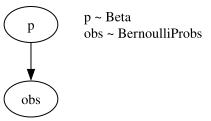

In [3]:
numpyro.render_model(one_throw_model, render_distributions=True)

## Sample from my model without data

In [4]:
key = jax.random.PRNGKey(0)

predictive = Predictive(one_throw_model, num_samples=10)
samples = predictive(key)

print(samples)

{'obs': Array([1, 0, 0, 1, 0, 1, 1, 0, 1, 1], dtype=int32), 'p': Array([0.21130668, 0.31980485, 0.3934319 , 0.5034159 , 0.66317576,
       0.8421861 , 0.9999993 , 0.13984579, 0.9525992 , 0.4448651 ],      dtype=float32)}


## Several iid coin throws

In [5]:
def n_throws_model(data: jax.Array | None = None, n: int = 10) -> None:
    p = numpyro.sample("p", dist.Beta(1.0, 1.0))

    with numpyro.plate("throws", n):
        numpyro.sample("obs", dist.Bernoulli(p), obs=data)

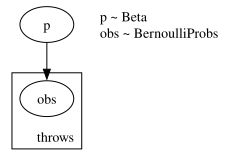

In [6]:
numpyro.render_model(n_throws_model, render_distributions=True)

In [7]:
key = jax.random.PRNGKey(0)

predictive = Predictive(n_throws_model, num_samples=5)
samples = predictive(key, n=10)
print(samples)

{'obs': Array([[1, 0, 0, 0, 1, 1, 0, 0, 1, 0],
       [0, 0, 0, 1, 0, 1, 0, 0, 0, 0],
       [0, 1, 1, 0, 1, 1, 0, 0, 0, 0],
       [1, 0, 0, 1, 1, 1, 1, 0, 1, 0],
       [0, 1, 1, 1, 0, 0, 1, 0, 0, 0]], dtype=int32), 'p': Array([0.21130668, 0.31980485, 0.3934319 , 0.5034159 , 0.66317576],      dtype=float32)}


## Doing inference from data

In [8]:
data = jnp.array([0, 1, 0, 1, 1, 0, 1, 0, 1, 1])

In [9]:
kernel = NUTS(n_throws_model)
mcmc = MCMC(kernel, num_warmup=500, num_samples=10000, num_chains=4,)
mcmc.run(jax.random.PRNGKey(0), data=data, n=len(data))
mcmc.print_summary()

  0%|          | 0/10500 [00:00<?, ?it/s]

  0%|          | 0/10500 [00:00<?, ?it/s]

  0%|          | 0/10500 [00:00<?, ?it/s]

  0%|          | 0/10500 [00:00<?, ?it/s]


                mean       std    median      5.0%     95.0%     n_eff     r_hat
         p      0.58      0.14      0.59      0.36      0.81  15599.44      1.00

Number of divergences: 0


In [ ]:
posterior_samples = mcmc.get_samples()

In [ ]:

plt.figure()
plt.hist(posterior_samples["p"], bins=40, density=True, alpha=0.7)
plt.xlabel("p")
plt.ylabel("density")
plt.show()

## Sample from the posterior predictive distribution

In [ ]:
posterior_predictive = Predictive(n_throws_model, posterior_samples=posterior_samples)
new_samples = posterior_predictive(jax.random.PRNGKey(1), n=10)